In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/emelyneishimwe/school-data/Country Schools.csv


# Question
For country schools dataset, perform basic data preprocessing activities and then run the experiments and interpret the output on the following topics
1. anomaly detection
2. Cluster analysis

In [2]:
data = pd.read_csv('/kaggle/input/datasets/emelyneishimwe/school-data/Country Schools.csv')
data.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [3]:
# Check for null values per column
print("Missing values per column:")
print(data.isnull().sum())

# Inspect rows containing nulls
print("\nRows with missing values:")
print(data[data.isnull().any(axis=1)])


Missing values per column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Rows with missing values:
    SNO  TOTALSCHOOLS  TotalSchoolsInstalled  SchoolsPending  \
48  NaN           NaN                    NaN             NaN   
49  NaN           NaN                    NaN             NaN   

   PercentageInstalled  InstalledLDDs  InstalledTDDs  FID  
48                 NaN            NaN            NaN   49  
49                 NaN            NaN            NaN   50  


In [4]:
df = data.copy()

In [5]:
# Drop rows where essential columns are NaN
df = df.dropna(subset=['SNO', 'TOTALSCHOOLS'])

# Check shape after dropping NaNs
print("Shape after dropping NaN rows:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

Shape after dropping NaN rows: (48, 8)
Missing values remaining: 0


In [6]:
# Convert PercentageInstalled from string (e.g., '10.34%') to float
if df['PercentageInstalled'].dtype == object:
    df['PercentageInstalled'] = df['PercentageInstalled'].str.replace('%', '', regex=False).astype(float)

# Inspect data types and sample data after cleaning
print(df[['SNO', 'PercentageInstalled']].head())
print("\nUpdated Data Types:")
print(df.dtypes)

          SNO  PercentageInstalled
0     TURKANA                10.34
1    HOMA BAY                63.09
2  WEST POKOT                48.59
3       KITUI                96.93
4  TANA RIVER                89.94

Updated Data Types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled      float64
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object


# 1. Anomaly Detection


In [7]:
from sklearn.preprocessing import StandardScaler

# Select numeric features for anomaly detection (ignoring SNO and FID)
features = ['TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending', 'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs']
X = df[features]

# Standardize the features (mean = 0, variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected and scaled successfully!")
print("Number of rows/samples processed:", len(X_scaled))

Features selected and scaled successfully!
Number of rows/samples processed: 48


In [8]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest (contamination is the expected proportion of outliers, e.g., 10% or 0.1)
iso_forest = IsolationForest(contamination=0.1, random_state=42)

# Fit the model and predict anomalies (-1 indicates an anomaly/outlier, 1 indicates normal)
df['Anomaly_Score'] = iso_forest.fit_predict(X_scaled)

# Count how many normal vs anomalous counties were found
print("Anomaly prediction counts:")
print(df['Anomaly_Score'].value_counts())

Anomaly prediction counts:
Anomaly_Score
 1    43
-1     5
Name: count, dtype: int64


In [9]:
# Filter and display the rows flagged as anomalies (Anomaly_Score == -1)
anomalies = df[df['Anomaly_Score'] == -1]

print(f"Number of anomalies detected: {len(anomalies)}")
print("\nAnomalous Counties:")
print(anomalies[['SNO', 'TOTALSCHOOLS', 'TotalSchoolsInstalled', 'PercentageInstalled']])

Number of anomalies detected: 5

Anomalous Counties:
         SNO  TOTALSCHOOLS  TotalSchoolsInstalled  PercentageInstalled
0    TURKANA         358.0                   37.0                10.34
3      KITUI        1238.0                 1200.0                96.93
13   MAKUENI         887.0                  833.0                93.91
17  KAKAMEGA         880.0                  572.0                65.00
47     TOTAL       21729.0                14629.0                67.32


### Analysis and Interpretation of Country Schools Dataset

1. Anomaly Detection Analysis

The Isolation Forest algorithm identified 5 anomalies out of 48 records in the dataset:

Turkana: Extremely low completion rate (10.34%) with a severe backlog of pending schools.

Kitui & Makueni: Unusually high installation rates (96.93% and 93.91%) alongside high volumes of installed devices compared to other counties.

Kakamega: High total number of schools (880) but lagging installation progress (65.00%).

TOTAL: The national summary row. It was flagged as an anomaly because its raw values (21,729 schools) are far higher than any individual county.

# 2. Cluster Analysis

we will use the K-Means Clustering algorithm

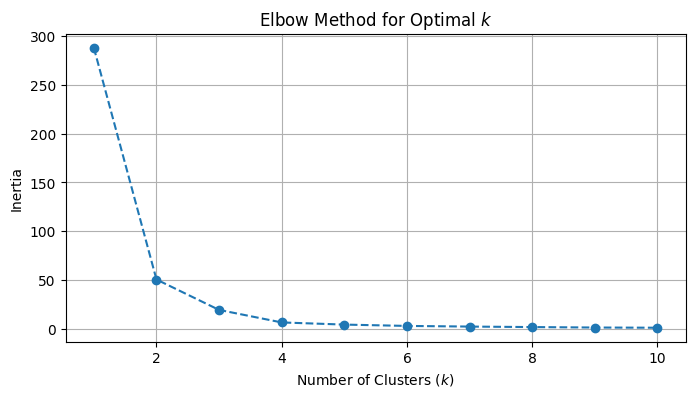

In [10]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate inertia (Sum of squared distances) for different number of clusters (k from 1 to 10)
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal $k$')
plt.xlabel('Number of Clusters ($k$)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [11]:
# Initialize and fit K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# View the count of counties in each cluster
print("Count of counties per cluster:")
print(df['Cluster'].value_counts())

Count of counties per cluster:
Cluster
0    33
2    14
1     1
Name: count, dtype: int64


In [12]:
# Calculate the average values of each feature for each cluster to interpret what each cluster represents
cluster_summary = df.groupby('Cluster')[features].mean()

print("Cluster Summary (Average values per cluster):")
print(cluster_summary)

Cluster Summary (Average values per cluster):
         TOTALSCHOOLS  TotalSchoolsInstalled  SchoolsPending  \
Cluster                                                        
0          488.909091             376.000000      112.909091   
1        21729.000000           14629.000000     7100.000000   
2          399.642857             158.642857      241.000000   

         PercentageInstalled  InstalledLDDs  InstalledTDDs  
Cluster                                                     
0                  77.222727   19074.242424     752.000000  
1                  67.320000  723618.000000   29258.000000  
2                  32.560714    6726.285714     317.285714  


In [13]:
# Inspect a few counties and their assigned clusters
print(df[['SNO', 'Cluster', 'TOTALSCHOOLS', 'PercentageInstalled']].head(15))

             SNO  Cluster  TOTALSCHOOLS  PercentageInstalled
0        TURKANA        2         358.0                10.34
1       HOMA BAY        0         875.0                63.09
2     WEST POKOT        2         498.0                48.59
3          KITUI        0        1238.0                96.93
4     TANA RIVER        0         159.0                89.94
5   TAITA TAVETA        0         194.0                88.66
6    UASIN GISHU        0         456.0                77.41
7         MIGORI        0         601.0                68.72
8         VIHIGA        0         378.0                81.22
9        NYAMIRA        0         406.0                86.45
10         NAROK        0         616.0                93.02
11         NANDI        0         709.0                94.92
12       MOMBASA        0          96.0                89.58
13       MAKUENI        0         887.0                93.91
14          LAMU        0          93.0                95.70


### Cluster Analysis Analysis
Using K-Means Clustering (k = 3), the counties were grouped into three distinct categories based on their school infrastructure progress:
    
* **Cluster 0** High-Performing Counties (33 Counties)
    * Average Progress: ~77.2% installed.
    * Characteristics: Moderate school counts with steady, successful                          infrastructure deployment (e.g., Kitui, Makueni, Tana River).
 
* **Cluster 1** National Aggregate (1 Row):
  *  Characteristics: Contains only the TOTAL summary row due to its massive scale compared to individual counties.
* **Cluster 2** Lagging / Under-Resourced Counties (14 Counties):
  * Average Progress: ~32.6% installed.
  *  Characteristics: High backlog of pending schools and low device deployment (e.g., Turkana, West Pokot).
